# FASTA2GO — correlation matrices

Explores how the most frequent keyword terms (`words` and `phrases` from
`protein_keyword_terms`) co-occur across the 575,748 proteins, and how those
terms relate to amino-acid composition.

Matrices produced:

* **Phi coefficient** — Pearson correlation of binary presence vectors.
  `+1` = always together, `-1` = mutually exclusive, `0` = independent.
* **Jaccard** — `|A ∩ B| / |A ∪ B|`, pure overlap regardless of prevalence.
* **Amino acids vs terms** — point-biserial Pearson `r` between each amino
  acid percentage and term presence.

Prerequisites: run `scripts/build_keyword_terms.py` first so
`protein_keyword_terms` exists in `proteins.duckdb`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "protein_database").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from protein_database.db import connect
from protein_database.schema import AMINO_ACIDS
from scripts.amino_acid_correlations import (
    correlation_chunks,
    correlation_matrix_chunks,
)
from scripts.term_correlations import (
    jaccard_matrix,
    phi_matrix,
    presence_matrix,
    top_terms,
)

DB_PATH = PROJECT_ROOT / "proteins.duckdb"
TOP = 50

sns.set_theme(style="white", context="notebook")
plt.rcParams["figure.dpi"] = 110

conn = connect(DB_PATH)
print(f"database: {DB_PATH}")
print(f"terms per kind: {TOP}")

database: /home/orfeu/Documents/github/FASTA2GO/proteins.duckdb
terms per kind: 50


In [2]:
words = top_terms(conn, "words", TOP)
phrases = top_terms(conn, "phrases", TOP)

pd.DataFrame({
    "rank": range(1, TOP + 1),
    "word": words,
    "phrase": phrases,
}).head(15)

,rank,word,phrase
0,1,binding,plasma_membrane
1,2,cytoplasm,atp_binding
2,3,catalyzes,structural_constituent_ribosome
3,4,membrane,extracellular_region
4,5,biosynthetic,magnesium_ion_binding
5,6,cytosol,dna_binding
6,7,atp,rrna_binding
7,8,ion,zinc_ion_binding
8,9,cell,rna_binding
9,10,regulation,cytosolic_large_ribosomal_subunit


## 1. Word co-occurrence

In [3]:
word_presence = presence_matrix(conn, "words", words)
word_phi = phi_matrix(word_presence)
word_jaccard = jaccard_matrix(word_presence)

word_phi_df = pd.DataFrame(word_phi, index=words, columns=words)
word_phi_df.iloc[:6, :6].round(3)

,binding,cytoplasm,catalyzes,membrane,biosynthetic,cytosol
binding,1.000,0.122,0.053,-0.139,-0.015,0.125
cytoplasm,0.122,1.000,0.076,-0.133,0.081,-0.133
catalyzes,0.053,0.076,1.000,-0.131,0.434,0.165
membrane,-0.139,-0.133,-0.131,1.000,-0.078,-0.118
biosynthetic,-0.015,0.081,0.434,-0.078,1.000,0.111
cytosol,0.125,-0.133,0.165,-0.118,0.111,1.000


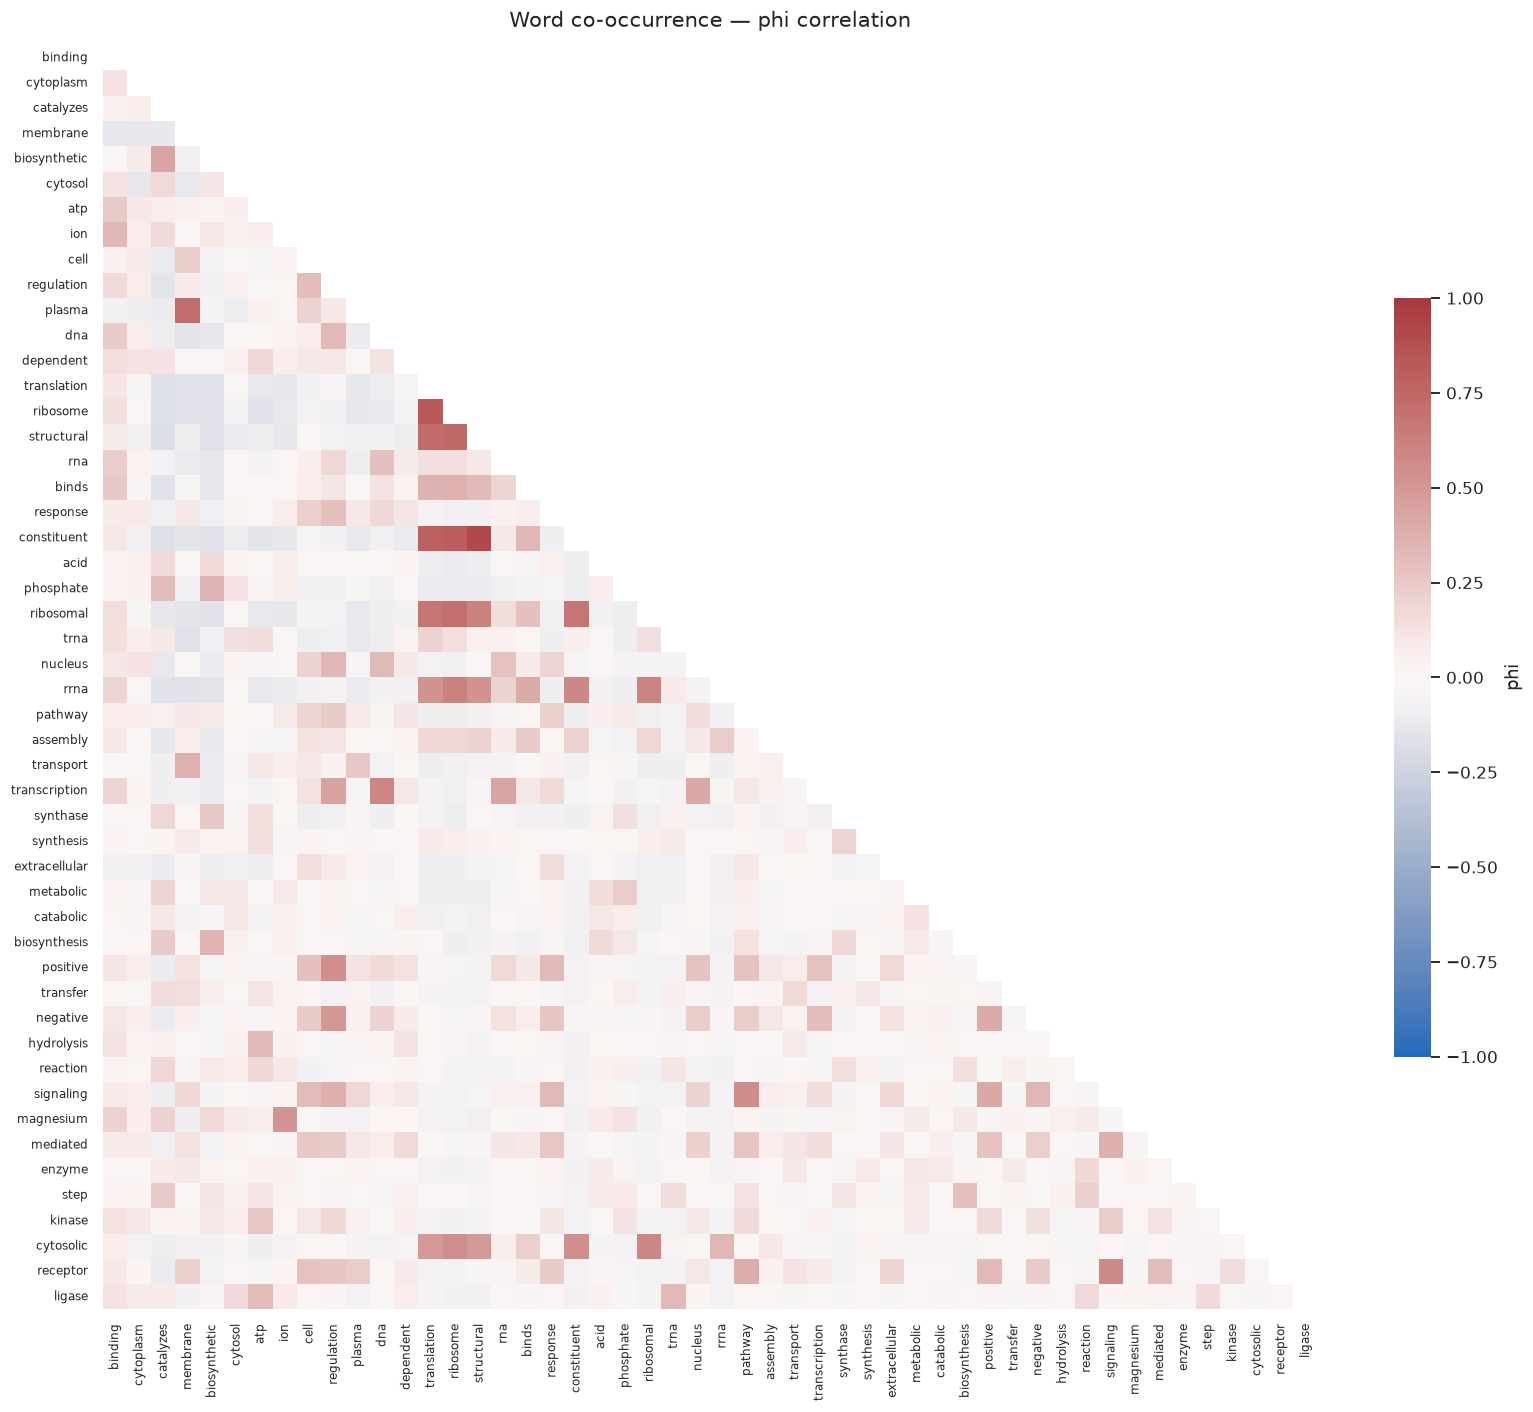

In [4]:
limit = float(np.abs(word_phi).max())
mask = np.triu(np.ones_like(word_phi, dtype=bool), k=0)

fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(
    word_phi_df,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0,
    cbar_kws={"shrink": 0.6, "label": "phi"},
    ax=ax,
)
ax.set_title("Word co-occurrence — phi correlation", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [5]:
def pair_table(terms, matrix, n=12):
    """Long-format table of off-diagonal pairs, strongest positive first."""
    pairs = [
        (terms[i], terms[j], float(matrix[i, j]))
        for i in range(len(terms))
        for j in range(i + 1, len(terms))
    ]
    table = pd.DataFrame(pairs, columns=["term_a", "term_b", "value"])
    return table.sort_values("value", ascending=False).head(n).reset_index(drop=True)


pair_table(words, word_phi).round(3)

,term_a,term_b,value
0,structural,constituent,0.912
1,translation,ribosome,0.831
2,ribosome,constituent,0.809
3,translation,constituent,0.784
4,ribosome,structural,0.741
5,translation,structural,0.731
6,membrane,plasma,0.724
7,ribosome,ribosomal,0.718
8,translation,ribosomal,0.682
9,constituent,ribosomal,0.673


In [6]:
# Most mutually exclusive word pairs (tail of the same ranking).
pairs = [
    (words[i], words[j], float(word_phi[i, j]))
    for i in range(len(words))
    for j in range(i + 1, len(words))
]
pd.DataFrame(pairs, columns=["term_a", "term_b", "phi"]).nsmallest(8, "phi").round(3)

,term_a,term_b,phi
109,catalyzes,structural,-0.185
113,catalyzes,constituent,-0.174
108,catalyzes,ribosome,-0.170
107,catalyzes,translation,-0.168
153,membrane,translation,-0.163
198,biosynthetic,translation,-0.163
163,membrane,trna,-0.159
200,biosynthetic,structural,-0.159


## 2. Phrase co-occurrence

In [7]:
phrase_presence = presence_matrix(conn, "phrases", phrases)
phrase_phi = phi_matrix(phrase_presence)
phrase_jaccard = jaccard_matrix(phrase_presence)

phrase_phi_df = pd.DataFrame(phrase_phi, index=phrases, columns=phrases)
phrase_phi_df.iloc[:6, :6].round(3)

,plasma_membrane,atp_binding,structural_constituent_ribosome,extracellular_region,magnesium_ion_binding,dna_binding
plasma_membrane,1.000,0.028,-0.117,-0.020,-0.069,-0.070
atp_binding,0.028,1.000,-0.116,-0.086,0.079,-0.007
structural_constituent_ribosome,-0.117,-0.116,1.000,-0.077,-0.070,-0.066
extracellular_region,-0.020,-0.086,-0.077,1.000,-0.030,-0.048
magnesium_ion_binding,-0.069,0.079,-0.070,-0.030,1.000,-0.002
dna_binding,-0.070,-0.007,-0.066,-0.048,-0.002,1.000


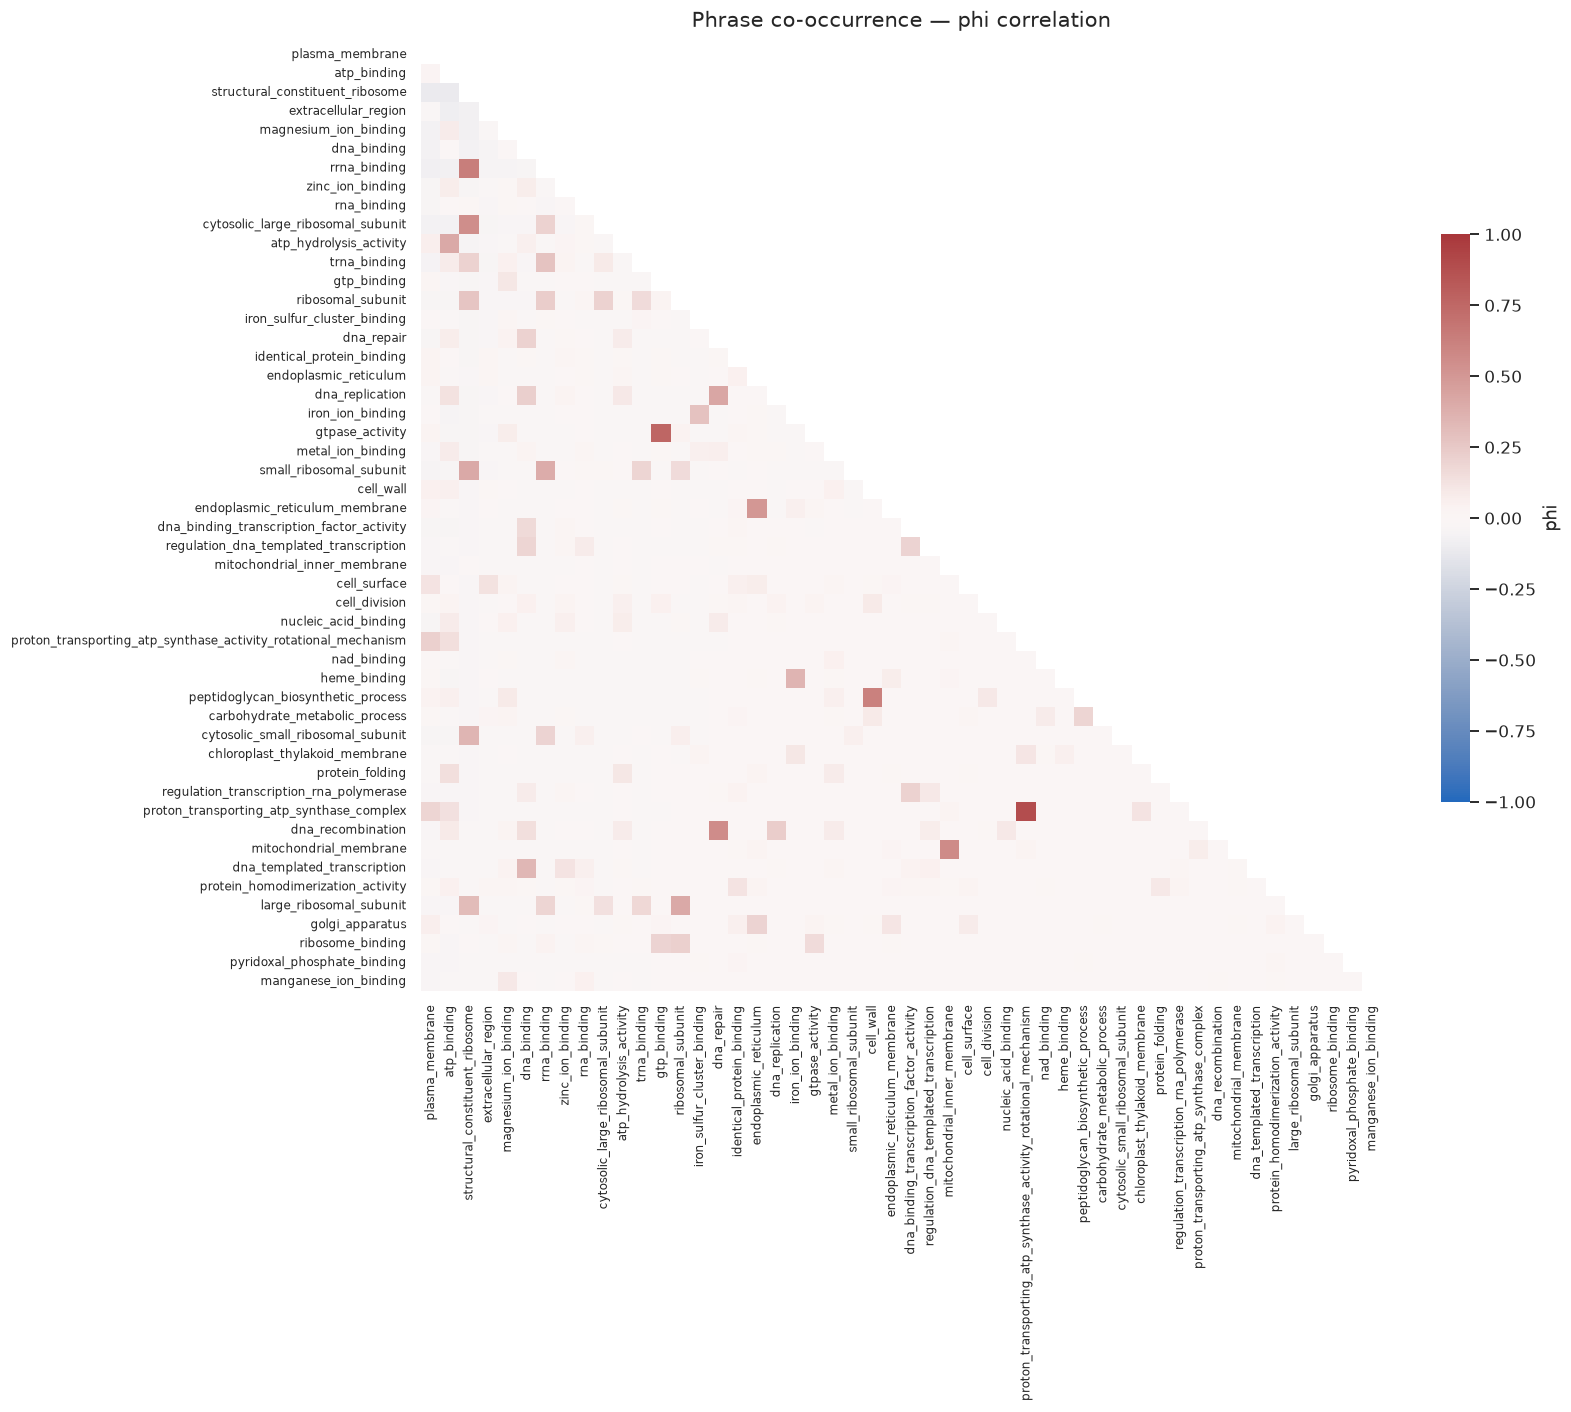

In [8]:
limit = float(np.abs(phrase_phi).max())
mask = np.triu(np.ones_like(phrase_phi, dtype=bool), k=0)

fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(
    phrase_phi_df,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0,
    cbar_kws={"shrink": 0.6, "label": "phi"},
    ax=ax,
)
ax.set_title("Phrase co-occurrence — phi correlation", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [9]:
pair_table(phrases, phrase_phi).round(3)

,term_a,term_b,value
0,proton_transporting_atp_synthase_activity_rota...,proton_transporting_atp_synthase_complex,0.886
1,gtp_binding,gtpase_activity,0.760
2,structural_constituent_ribosome,rrna_binding,0.635
3,cell_wall,peptidoglycan_biosynthetic_process,0.624
4,mitochondrial_inner_membrane,mitochondrial_membrane,0.568
5,dna_repair,dna_recombination,0.556
6,structural_constituent_ribosome,cytosolic_large_ribosomal_subunit,0.550
7,endoplasmic_reticulum,endoplasmic_reticulum_membrane,0.506
8,dna_repair,dna_replication,0.422
9,atp_binding,atp_hydrolysis_activity,0.410


In [10]:
# Jaccard is prevalence-insensitive, so rare concepts show their overlap.
phrase_jaccard_df = pd.DataFrame(phrase_jaccard, index=phrases, columns=phrases)
pair_table(phrases, phrase_jaccard).round(3)

,term_a,term_b,value
0,proton_transporting_atp_synthase_activity_rota...,proton_transporting_atp_synthase_complex,0.792
1,gtp_binding,gtpase_activity,0.609
2,cell_wall,peptidoglycan_biosynthetic_process,0.451
3,structural_constituent_ribosome,rrna_binding,0.450
4,mitochondrial_inner_membrane,mitochondrial_membrane,0.395
5,dna_repair,dna_recombination,0.366
6,endoplasmic_reticulum,endoplasmic_reticulum_membrane,0.344
7,structural_constituent_ribosome,cytosolic_large_ribosomal_subunit,0.323
8,dna_repair,dna_replication,0.276
9,ribosomal_subunit,large_ribosomal_subunit,0.239


## 3. Amino-acid composition vs terms

Each cell is the Pearson correlation (point-biserial) between one amino
acid's percentage in the protein and whether the term is present. Percentages
are compositional (they sum to 100 per protein), so the 20 rows are not
statistically independent.

In [11]:
amino_acids = list(AMINO_ACIDS.values())

aa_words = correlation_matrix_chunks(
    correlation_chunks(conn, "words", words, batch_size=25_000)
)
aa_phrases = correlation_matrix_chunks(
    correlation_chunks(conn, "phrases", phrases, batch_size=25_000)
)

aa_words_df = pd.DataFrame(aa_words, index=amino_acids, columns=words)
aa_phrases_df = pd.DataFrame(aa_phrases, index=amino_acids, columns=phrases)
aa_words_df.iloc[:, :6].round(3)

,binding,cytoplasm,catalyzes,membrane,biosynthetic,cytosol
alanine,0.021,0.006,0.128,-0.034,0.133,0.042
arginine,0.103,-0.010,-0.072,-0.159,-0.049,-0.027
asparagine,-0.028,-0.035,-0.063,-0.015,-0.073,-0.019
aspartic_acid,0.115,0.118,0.103,-0.237,0.074,0.134
cysteine,-0.074,-0.040,-0.059,-0.002,-0.054,-0.067
glutamine,0.042,0.033,-0.096,-0.022,-0.083,0.026
glutamic_acid,0.163,0.122,0.003,-0.246,-0.011,0.141
glycine,0.032,0.009,0.136,-0.032,0.106,0.019
histidine,0.040,0.038,0.070,-0.098,0.060,0.008
isoleucine,-0.039,-0.007,0.064,0.102,0.057,-0.004


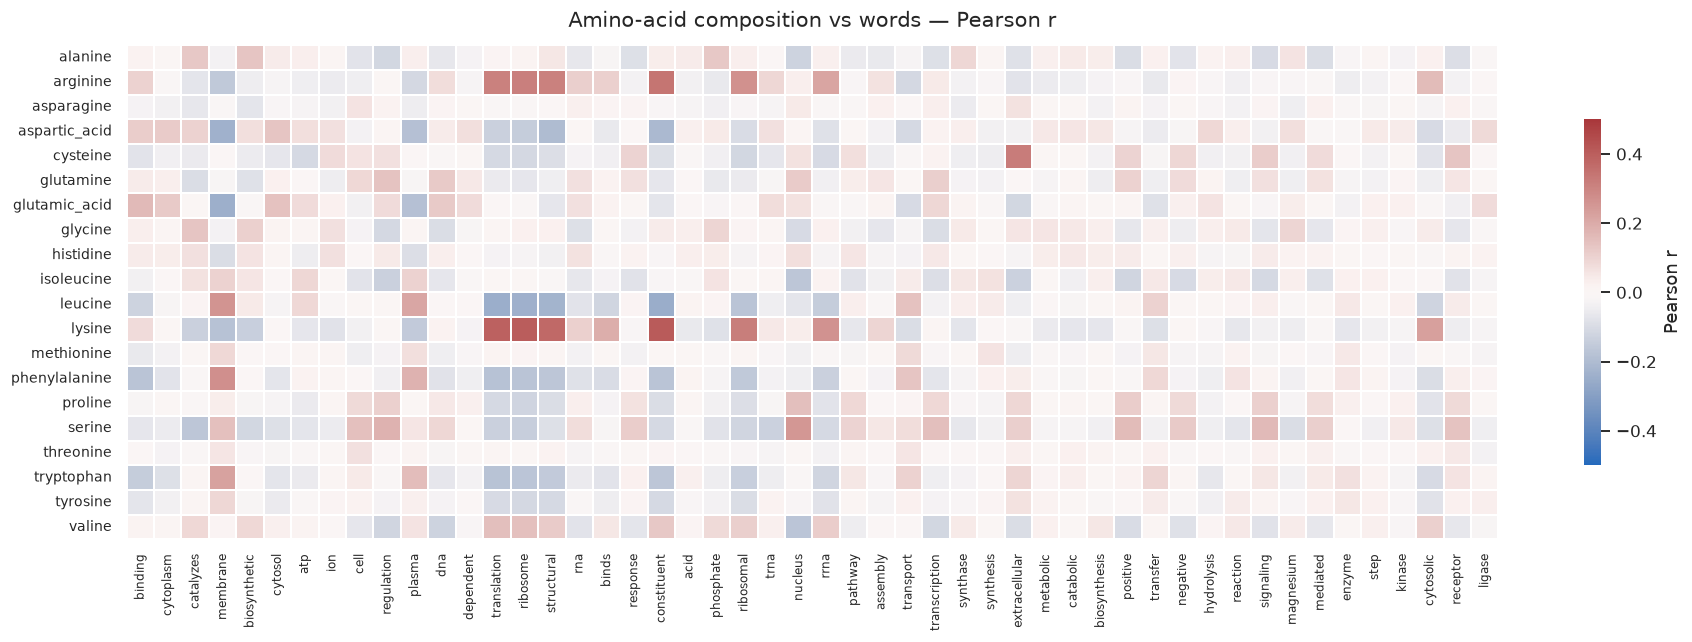

In [12]:
fig, ax = plt.subplots(figsize=(17, 6))
sns.heatmap(
    aa_words_df,
    cmap="vlag",
    center=0,
    vmin=-0.5,
    vmax=0.5,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.set_title("Amino-acid composition vs words — Pearson r", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.show()

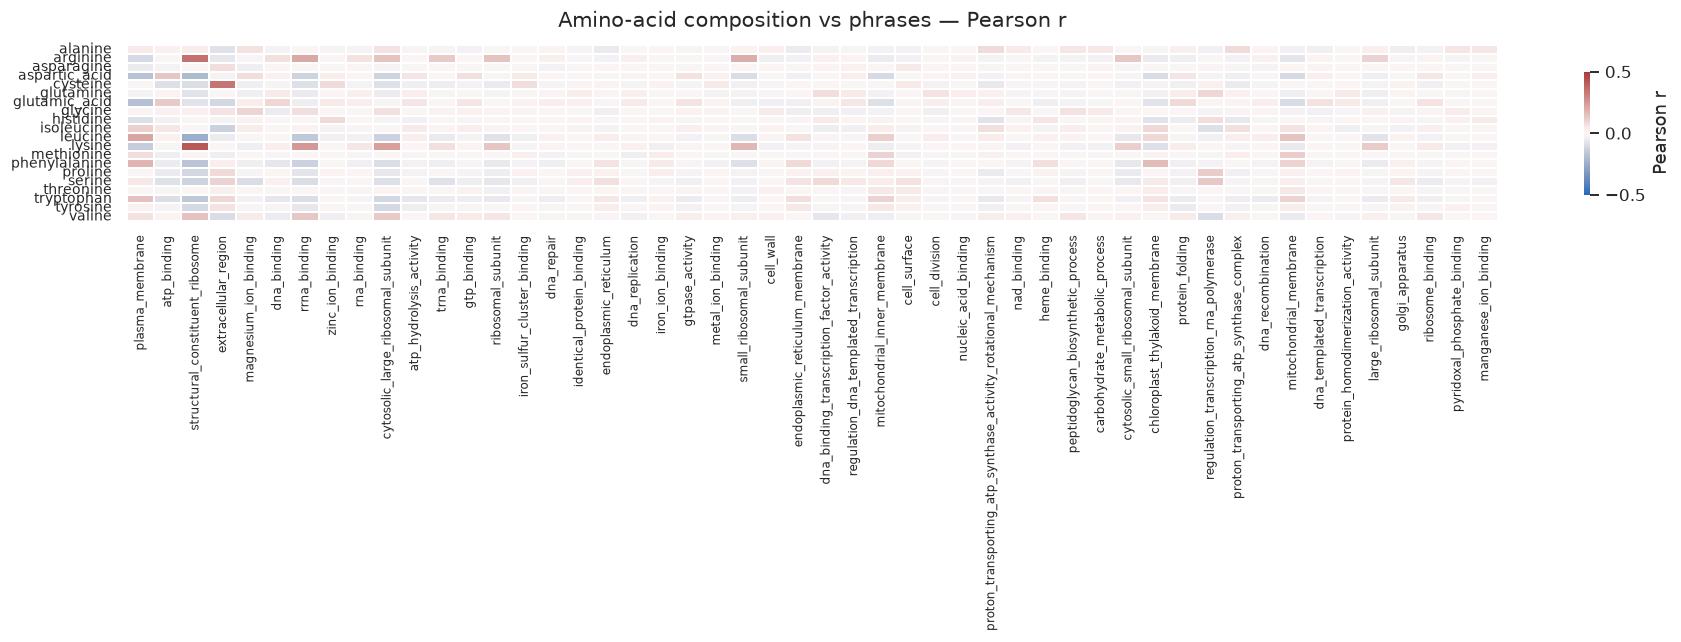

In [13]:
fig, ax = plt.subplots(figsize=(17, 6))
sns.heatmap(
    aa_phrases_df,
    cmap="vlag",
    center=0,
    vmin=-0.5,
    vmax=0.5,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.set_title("Amino-acid composition vs phrases — Pearson r", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.show()

In [14]:
# Strongest absolute associations, regardless of sign.
flat = [
    (amino_acids[i], phrases[j], float(aa_phrases[i, j]))
    for i in range(len(amino_acids))
    for j in range(len(phrases))
]
strongest = pd.DataFrame(flat, columns=["amino_acid", "phrase", "r"])
strongest["abs_r"] = strongest["r"].abs()
strongest.sort_values("abs_r", ascending=False).head(15).drop(columns="abs_r").round(3)

,amino_acid,phrase,r
552,lysine,structural_constituent_ribosome,0.418
52,arginine,structural_constituent_ribosome,0.353
203,cysteine,extracellular_region,0.338
502,leucine,structural_constituent_ribosome,-0.248
556,lysine,rrna_binding,0.247
559,lysine,cytosolic_large_ribosomal_subunit,0.229
500,leucine,plasma_membrane,0.212
56,arginine,rrna_binding,0.211
152,aspartic_acid,structural_constituent_ribosome,-0.203
72,arginine,small_ribosomal_subunit,0.194


## 4. Optional export

Flip `SAVE_FIGURES` to write the current figures to
`exports/correlations/plots/notebook/` as PNGs.

In [15]:
SAVE_FIGURES = False
OUT_DIR = PROJECT_ROOT / "exports" / "correlations" / "plots" / "notebook"

if SAVE_FIGURES:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for number, figure in enumerate(plt.get_fignums(), start=1):
        plt.figure(figure).savefig(OUT_DIR / f"figure_{number:02d}.png", dpi=200)
    print(f"saved {len(plt.get_fignums())} figures to {OUT_DIR}")
else:
    print("export disabled (set SAVE_FIGURES = True)")

export disabled (set SAVE_FIGURES = True)


In [16]:
conn.close()